# FIREGUARD ID — 02: Spatial Grid (0.1°) & Locked Feature Engineering

            - Uses `src/geospatial/geometry.py` (`build_fishnet_grid`, `geodesic_area_km2`) and `src/features/engineering.py` (`assign_hotspots_to_grid`, `build_analytical_grid_dataset`, `preprocess_clustering_matrix`).
            - Enforces locked feature schema **`v2.0.0`** from `config/features.yaml`:
              `['hotspot_density_km2', 'fire_days', 'active_years_count', 'frp_total_density_mw_km2']`.
            - Enforces leakage guard via `validate_no_leakage_columns()` so QA metadata (`high_conf_share`, `has_zero_detections`), spatial coordinates, cluster IDs, and optimization fields never enter clustering inputs.


In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_ROOT / ".mplconfig"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_yaml, resolve_path

proj_cfg = load_yaml("config/project.yaml", repo_root=REPO_ROOT)
print(f"Project: {proj_cfg['project']['name']} v{proj_cfg['project']['version']} | Pilot: {proj_cfg['project']['pilot_region']}")

from src.data.quality import validate_no_leakage_columns
from src.features.engineering import build_analytical_grid_dataset, preprocess_clustering_matrix
from src.features.pipeline import run_phase3_feature_pipeline


Project: FIREGUARD-ID v2.0.0 | Pilot: Riau Province, Indonesia


## 1. Load Locked Feature Spec (`config/features.yaml`) & Verify Leakage Guard


In [2]:
features_cfg = load_yaml("config/features.yaml", repo_root=REPO_ROOT)
print("Schema Version:", features_cfg["schema_version"], "| Locked:", features_cfg["locked"])
print("Clustering Features:", features_cfg["clustering_features"])
print("log1p Transforms:", features_cfg["transforms"]["log1p"])

validate_no_leakage_columns(features_cfg["clustering_features"], features_cfg)
print("Leakage guard check passed for locked clustering features.")

# Confirm forbidden columns raise ValueError if passed
try:
    validate_no_leakage_columns(["hotspot_density_km2", "high_conf_share"], features_cfg)
except ValueError as exc:
    print("Leakage guard rejected forbidden column as expected:", exc)


Schema Version: 2.0.0 | Locked: True
Clustering Features: ['hotspot_density_km2', 'fire_days', 'active_years_count', 'frp_total_density_mw_km2']
log1p Transforms: ['hotspot_density_km2', 'fire_days', 'frp_total_density_mw_km2']
Leakage guard check passed for locked clustering features.


## 2. Inspect Analytical Grid & Scaled Clustering Matrix (`853 × 4`)


In [3]:
processed_dir = resolve_path(proj_cfg["paths"]["processed_dir"], repo_root=REPO_ROOT)
split_dir = resolve_path(proj_cfg["paths"]["split_dir"], repo_root=REPO_ROOT)
reports_dir = resolve_path(proj_cfg["paths"]["reports_dir"], repo_root=REPO_ROOT)

df_grid = pd.read_parquet(processed_dir / "riau_grid_analytical.parquet")
df_scaled = pd.read_parquet(processed_dir / "clustering_matrix_scaled.parquet")
meta = json.loads((reports_dir / "data_quality" / "feature_dataset_metadata.json").read_text(encoding="utf-8"))

print(f"Analytical Grid Shape: {df_grid.shape} | Scaled Matrix Shape: {df_scaled.shape}")
print(f"Nulls in Scaled Clustering Matrix: {int(df_scaled.isna().sum().sum())}")
print("Undefined conditional NaNs (zero-detection cells preserved as NaN):", meta["undefined_conditional_nans"])
print("Spatial generalization blocks:", meta["spatial_blocks"])

for b in sorted(meta["spatial_blocks"]):
    tr = pd.read_parquet(split_dir / f"spatial_fold_{b}_train.parquet")
    te = pd.read_parquet(split_dir / f"spatial_fold_{b}_test.parquet")
    assert len(tr) + len(te) == len(df_grid)
print("Verified all 4 leave-one-quadrant-out spatial folds sum to 853 cells.")


Analytical Grid Shape: (853, 36) | Scaled Matrix Shape: (853, 5)
Nulls in Scaled Clustering Matrix: 0
Undefined conditional NaNs (zero-detection cells preserved as NaN): {'mean_frp_mw': 249, 'max_frp_mw': 249, 'frp_p90_mw': 249, 'dry_season_share': 249, 'night_detection_share': 249, 'high_conf_share': 249}
Spatial generalization blocks: {'NE': 150, 'NW': 281, 'SE': 293, 'SW': 129}
Verified all 4 leave-one-quadrant-out spatial folds sum to 853 cells.


## 3. Correlation & Feature Distribution Diagnostics


,hotspot_density_km2,fire_days,active_years_count,frp_total_density_mw_km2
hotspot_density_km2,1.0000,0.6995,0.5351,0.9047
fire_days,0.6995,1.0000,0.9244,0.6890
active_years_count,0.5351,0.9244,1.0000,0.5662
frp_total_density_mw_km2,0.9047,0.6890,0.5662,1.0000


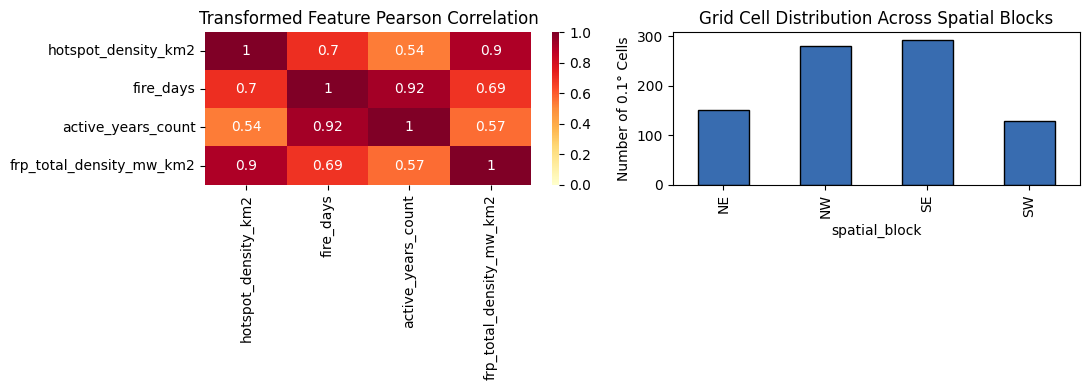

In [4]:
corr = pd.read_csv(reports_dir / "data_quality" / "feature_correlation_matrix.csv", index_col=0)
display(corr)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(corr, annot=True, cmap="YlOrRd", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Transformed Feature Pearson Correlation")

df_grid["spatial_block"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#386cb0", edgecolor="black")
axes[1].set_title("Grid Cell Distribution Across Spatial Blocks")
axes[1].set_ylabel("Number of 0.1° Cells")
plt.tight_layout()
plt.show()
